# Hydroscope walkthrough: CNNs vs. a Vision Transformer, from EuroSAT to Aguascalientes

An optional companion to the paper, like the Hydroscope Explorer (`docs/explorer/`). It walks
through the results of **Hydroscope Aguascalientes** by running the code of this repository: every
number printed below is read from `experiments/results/*.json` and the EuroSAT training logs, through
the same functions that write the paper tables. No number is typed by hand, and the notebook writes
no file.

| Section | Topic | What to look at |
|---|---|---|
| 0 | Setup | Where the numbers come from and which model the protocol selected |
| 1 | The data | The EuroSAT classes and the two test sets |
| 2 | Results on EuroSAT (RQ-a) | Test scores and validation curves of every run |
| 3 | Drop and recovery (RQ-b, RQ-c) | How much each run loses in Aguascalientes and how much fine-tuning wins back |
| 4 | Confusion matrix | Which classes the models confuse, before and after fine-tuning |
| 5 | CNN vs. ViT, and what each one costs (RQ-a, RQ-d, RQ-e) | Score against cost, and the selection rule run live |
| 6 | Spatial split | Why the test cells are kept in separate blocks |
| 7 | Code tour (live) | The functions behind each step, called on tiny inputs |
| 8 | Conclusions | The three findings of the paper, with their numbers read from the results |

Every plot is a small function. Each cell first calls it with its default values (a static figure
that GitHub can show) and then calls it again through `ipywidgets.interact`, with menus to explore
the other runs when the notebook runs in Jupyter.

## 0. Setup

`build_explorer_data()` from `scripts/make_explorer_data.py` returns one dict with everything the
Explorer page shows. It is the only data source of this notebook. `ROOT` is the repository root, so the
notebook works when it is opened from `notebooks/` or from the root.

In [1]:
import json
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from ipywidgets import interact
from matplotlib.patches import Rectangle

ROOT = Path.cwd()
if not (ROOT / "scripts").exists():
    ROOT = ROOT.parent  # opened from notebooks/
sys.path.append(str(ROOT / "scripts"))

from make_explorer_basemap import PREFIX as BASEMAP_PREFIX
from make_explorer_data import NEIGHBOR_OFFSETS, build_explorer_data, count_test_touching_finetune
from make_paper_inputs import BLOCK_ALPHA, SPLIT_COLORS, SPLIT_NAMES
from make_results import (
    BANDS_NAMES,
    INIT_LINESTYLES,
    INIT_NAMES,
    LOGS_DIR,
    MODEL_COLORS,
    MODEL_NAMES,
    MODEL_ORDER,
    RESULTS_DIR,
    build_summary,
    draw_confusion,
    drop,
    last_block_shares,
    load_results,
    recovery,
    select_model,
)

# The scripts switch matplotlib to "Agg" (they only save PDFs); this brings the plots back here.
%matplotlib inline
# make_paper_inputs sets a smaller font for the paper; go back to the matplotlib default.
plt.rcParams["font.size"] = plt.rcParamsDefault["font.size"]
pd.set_option("display.precision", 3)  # three decimals, as in the paper

In [2]:
data = build_explorer_data()  # also prints its check of the spatial split (used by the Explorer)

runs = {run["run_id"]: run for run in data["runs"]}  # run_id -> run entry
winner = data["selection"]["all"]["winner"]  # protocol section 8, among all runs

print(f"evaluations: {data['inputs']['n_evaluations']} | runs: {len(runs)}")
print(f"results written by the code at commits: {', '.join(data['inputs']['result_commits'])}")
print(f"selected model: {runs[winner]['label']} ({winner})")

test cells touching a fine-tune cell (4 neighbours): 16
test cells touching a fine-tune cell (8 neighbours): 35
evaluations: 32 | runs: 8
results written by the code at commits: 371d227, 44436b3
selected model: ResNet-50 / MS13 / SSL4EO (resnet50_ms13_ssl4eo)


Each run is trained once on EuroSAT and then evaluated on the EuroSAT test set, on the
Aguascalientes test set without local training (zero-shot), and on the same test set after each of the
fine-tuning modes (`head` and `last_block`). The selected model is the run with the best
Aguascalientes macro-F1 after `last_block` fine-tuning.

## 1. The data

The Aguascalientes test set uses the EuroSAT land-use classes, labeled by hand with one label per grid
cell. The size of each test set is the sum of its confusion matrix (every test patch falls in
exactly one cell). Look at how unbalanced the Aguascalientes column is compared with EuroSAT: the
classes with too few test patches are reported separately and left out of the Aguascalientes macro-F1.

In [3]:
classes = data["classes"]
first_evaluations = data["runs"][0]["evaluations"]
# Row sums of a confusion matrix: test patches per true class, (10, 10) -> (10,)
eurosat_counts = np.array(first_evaluations["eurosat"]["confusion"]).sum(axis=1)
ags_counts = np.array(first_evaluations["zero_shot"]["confusion"]).sum(axis=1)  # (10,)

class_table = pd.DataFrame(
    {
        "EuroSAT test": eurosat_counts,
        "Aguascalientes test": ags_counts,
        "in Aguascalientes macro-F1": [name in data["macro_f1_classes"] for name in classes],
    },
    index=classes,
)
print(f"EuroSAT test patches: {eurosat_counts.sum()}")
print(f"Aguascalientes test patches: {ags_counts.sum()}")
class_table

EuroSAT test patches: 5400
Aguascalientes test patches: 541


,EuroSAT test,Aguascalientes test,in Aguascalientes macro-F1
AnnualCrop,596,104,True
Forest,608,40,True
HerbaceousVegetation,573,236,True
Highway,496,31,True
Industrial,501,24,True
Pasture,396,26,True
PermanentCrop,538,26,True
Residential,554,34,True
River,529,7,False
SeaLake,609,13,True


The Aguascalientes patches come from a Sentinel-2 composite of the state, built in Earth Engine. The image below is a mosaic of the RGB previews used for labeling, one small tile per grid
cell. It is written by `scripts/make_explorer_basemap.py` for the Explorer.

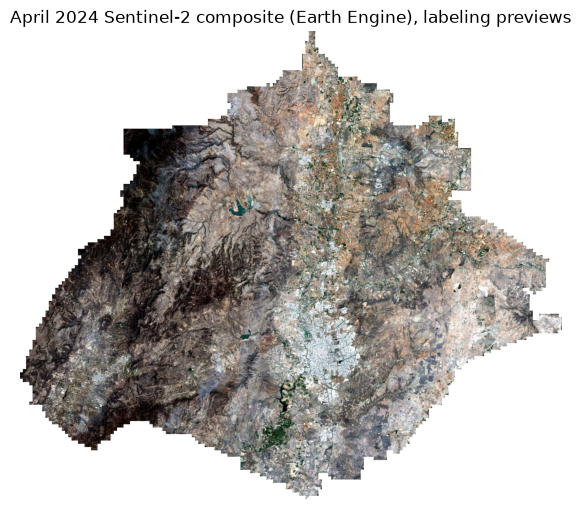

In [4]:
basemap_path = ROOT / "docs" / "explorer" / "basemap.jpg"
if basemap_path.exists():
    basemap = plt.imread(basemap_path)  # (H, W, 3)
    plt.figure(figsize=(7, 7))
    plt.imshow(basemap)
    plt.title("April 2024 Sentinel-2 composite (Earth Engine), labeling previews")
    plt.axis("off")
    plt.show()
else:
    print(f"{basemap_path.relative_to(ROOT)} not found.")
    print("Get the previews with: python scripts/download_release.py")
    print("then build the image with: python scripts/make_explorer_basemap.py")

## 2. Results on EuroSAT (RQ-a)

Each run combines an architecture (ResNet-50, EfficientNet-B0, ViT-S/16), an input (RGB or all the
Sentinel-2 bands) and pre-trained weights (ImageNet or SSL4EO-S12). All of them share the same training
protocol. `epochs` is the number of epochs actually trained (early stopping on the
validation macro-F1) and `epochs_to_95` is the first epoch that reached 95 % of the best validation
macro-F1. Look at how close the runs are on EuroSAT.

In [5]:
eurosat_table = pd.DataFrame(
    {
        "run": [run["label"] for run in data["runs"]],
        "accuracy": [run["summary"]["eurosat_accuracy"] for run in data["runs"]],
        "macro-F1": [run["summary"]["eurosat_macro_f1"] for run in data["runs"]],
        "epochs": [run["summary"]["epochs"] for run in data["runs"]],
        "epochs_to_95": [run["summary"]["epochs_to_95"] for run in data["runs"]],
    }
)
eurosat_table

,run,accuracy,macro-F1,epochs,epochs_to_95
0,ResNet-50 / RGB / ImageNet,0.984,0.983,15,2
1,ResNet-50 / MS13 / ImageNet,0.985,0.985,10,2
2,ResNet-50 / MS13 / SSL4EO,0.993,0.993,15,1
3,EfficientNet-B0 / RGB / ImageNet,0.984,0.984,12,2
4,EfficientNet-B0 / MS13 / ImageNet,0.985,0.985,15,2
5,ViT-S / RGB / ImageNet,0.991,0.991,15,1
6,ViT-S / MS13 / ImageNet,0.990,0.990,14,2
7,ViT-S / MS13 / SSL4EO,0.987,0.987,15,1


The validation curves, one panel per input. Color is the architecture and the line style is the
pre-trained weights (solid ImageNet, dashed SSL4EO-S12). Both panels share the vertical axis, so the
two inputs can be compared directly. Look at how many epochs each run needs to reach its plateau.

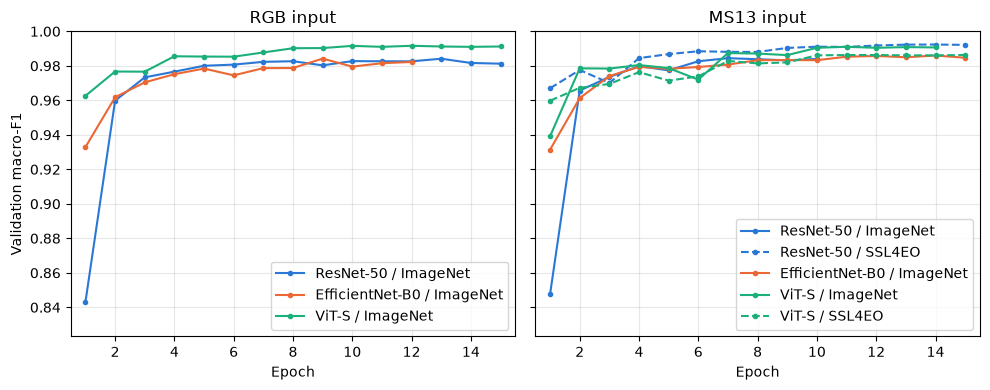

interactive(children=(Dropdown(description='metric', options=('val_macro_f1', 'val_accuracy'), value='val_macr…

In [6]:
METRIC_LABELS = {"val_macro_f1": "Validation macro-F1", "val_accuracy": "Validation accuracy"}


def curve_limits(metric):
    # Common vertical limits over every run (margin 0.02) and the longest run.
    lowest, highest, longest = 1.0, 0.0, 1
    for curve in data["curves"].values():
        lowest = min(lowest, min(curve[metric]))
        highest = max(highest, max(curve[metric]))
        longest = max(longest, max(curve["epoch"]))
    margin = 0.02
    return (max(0.0, lowest - margin), min(1.0, highest + margin)), longest


def plot_curves(metric="val_macro_f1"):
    # Validation metric per epoch, RGB runs on the left and 13-band runs on the right.
    y_limits, longest = curve_limits(metric)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
    for ax, bands in zip(axes, ["rgb", "ms13"], strict=True):
        for run in data["runs"]:
            if run["bands"] != bands or run["run_id"] not in data["curves"]:
                continue
            curve = data["curves"][run["run_id"]]
            ax.plot(
                curve["epoch"],
                curve[metric],
                INIT_LINESTYLES[run["init"]],
                marker="o",
                markersize=3,
                color=MODEL_COLORS[run["model"]],
                label=f"{MODEL_NAMES[run['model']]} / {INIT_NAMES[run['init']]}",
            )
        ax.set_ylim(*y_limits)
        ax.set_xlim(0.5, longest + 0.5)
        ax.set_xlabel("Epoch")
        ax.set_title(f"{BANDS_NAMES[bands]} input")
        ax.grid(alpha=0.3)
        ax.legend(loc="lower right", frameon=True)
    axes[0].set_ylabel(METRIC_LABELS[metric])
    plt.tight_layout()
    plt.show()


missing = [run_id for run_id in runs if run_id not in data["curves"]]
if missing:
    print(f"no training log for {missing}; get them with: python scripts/download_release.py")
plot_curves()
interact(plot_curves, metric=list(METRIC_LABELS));

## 3. Drop and recovery (RQ-b, RQ-c)

The paper measures the domain shift with two numbers (protocol section 7):

- **Drop** = F1 on EuroSAT − F1 on Aguascalientes zero-shot. Both F1 are averaged over the same classes
  (the classes of the Aguascalientes macro-F1), so the drop compares like with like.
- **Recovery** = (F1 after fine-tuning − F1 zero-shot) / Drop: 0 means fine-tuning won back nothing,
  1 means it closed the whole gap.

The cell below calls `drop()` and `recovery()` from `scripts/make_results.py`, the functions that
wrote the paper tables, and checks that the result matches the summary of that run.

In [7]:
def report_drop_recovery(run_id=winner):
    # Recompute drop and recovery of one run and compare them with its summary.
    summary = runs[run_id]["summary"]
    f1_eurosat = summary["eurosat_f1_macro_classes"]
    zero_shot = summary["ags_zero_shot"]
    drop_value = drop(f1_eurosat, zero_shot)
    print(runs[run_id]["label"])
    print(f"  drop = {f1_eurosat:.3f} - {zero_shot:.3f} = {drop_value:.3f}")
    print(f"  same as summary['drop']: {math.isclose(drop_value, summary['drop'])}")
    for mode in ["head", "last_block"]:
        fine_tuned = summary[f"ags_{mode}"]
        recovery_value = recovery(fine_tuned, zero_shot, drop_value)
        print(
            f"  recovery {mode} = ({fine_tuned:.3f} - {zero_shot:.3f}) / {drop_value:.3f}"
            f" = {recovery_value:.3f}"
        )
        same = math.isclose(recovery_value, summary[f"recovery_{mode}"])
        print(f"  same as summary['recovery_{mode}']: {same}")


report_drop_recovery()

ResNet-50 / MS13 / SSL4EO
  drop = 0.993 - 0.354 = 0.639
  same as summary['drop']: True
  recovery head = (0.372 - 0.354) / 0.639 = 0.029
  same as summary['recovery_head']: True
  recovery last_block = (0.525 - 0.354) / 0.639 = 0.268
  same as summary['recovery_last_block']: True


All the runs in one figure, as in the slides. Each row starts at the zero-shot score (orange dot).
The beige bar reaches the EuroSAT score (gray dot): its length is the drop. The teal bar reaches the
score after `last_block` fine-tuning (teal diamond): its length is what fine-tuning won back. Look at how
short the teal bars are compared with the beige ones.

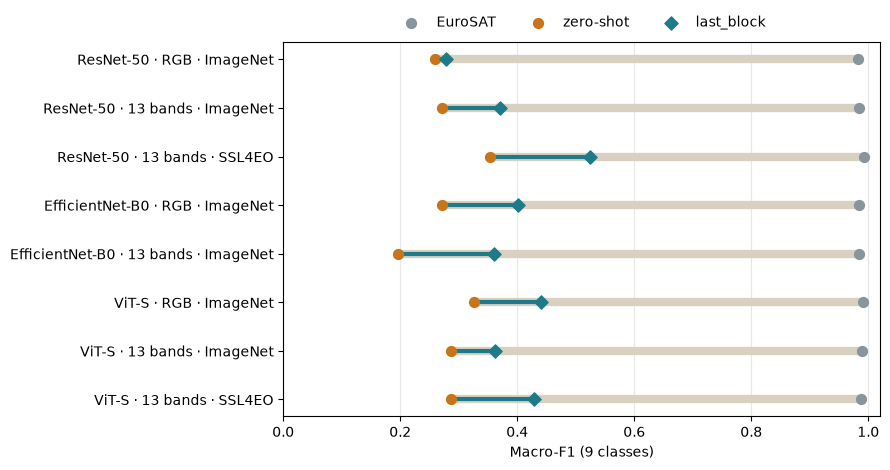

In [8]:
BANDS_LABELS = {"rgb": "RGB", "ms13": "13 bands"}  # wording of the slides and the Explorer


def plot_dumbbell():
    # Zero-shot -> EuroSAT (beige) and zero-shot -> last_block (teal), one row per run.
    labels, eurosat, zero_shot, last_block = [], [], [], []
    for run in data["runs"]:
        summary = run["summary"]
        names = [MODEL_NAMES[run["model"]], BANDS_LABELS[run["bands"]], INIT_NAMES[run["init"]]]
        labels.append(" · ".join(names))
        eurosat.append(summary["eurosat_f1_macro_classes"])
        zero_shot.append(summary["ags_zero_shot"])
        last_block.append(summary["ags_last_block"])
    rows = np.arange(len(labels))

    fig, ax = plt.subplots(figsize=(9, 4.8))
    ax.hlines(rows, zero_shot, eurosat, color="#D8D1C2", linewidth=6)
    ax.hlines(rows, zero_shot, last_block, color="#1E7A88", linewidth=3)
    ax.scatter(eurosat, rows, color="#8A949C", s=50, zorder=3, label="EuroSAT")
    ax.scatter(zero_shot, rows, color="#C7741A", s=50, zorder=3, label="zero-shot")
    ax.scatter(last_block, rows, color="#1E7A88", marker="D", s=45, zorder=3, label="last_block")
    ax.set_yticks(rows)
    ax.set_yticklabels(labels)
    ax.invert_yaxis()  # first run on top
    ax.set_xlim(0, 1.02)
    ax.set_xlabel(f"Macro-F1 ({len(data['macro_f1_classes'])} classes)")
    ax.grid(axis="x", alpha=0.3)
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False)
    plt.tight_layout()
    plt.show()


plot_dumbbell()

Pick any run to recompute its drop and its recovery after each fine-tuning mode (`head` trains only the
classifier, `last_block` also the last block of the backbone).

In [9]:
run_options = [(run["label"], run["run_id"]) for run in data["runs"]]  # (menu text, value)
interact(report_drop_recovery, run_id=run_options);

interactive(children=(Dropdown(description='run_id', index=2, options=(('ResNet-50 / RGB / ImageNet', 'resnet5…

## 4. Confusion matrix

Rows are the true classes and columns the predicted ones. The color is the row-normalized value (the
recall of that class), so rare and frequent classes are on the same scale; the number in each cell is
the count of test patches. The drawing is `draw_confusion()` from `scripts/make_results.py`, the same
function as the paper figure. Below each matrix, `largest_error()` names the most frequent mistake.

In [10]:
STAGE_TITLES = {
    "eurosat": "EuroSAT test",
    "zero_shot": "Aguascalientes zero-shot",
    "head": "Aguascalientes after head",
    "last_block": "Aguascalientes after last_block",
}


def largest_error(confusion):
    # Largest cell off the diagonal: (true class, predicted class, count, share of the true class).
    counts = np.array(confusion)
    best_i, best_j = 0, 1
    for i in range(len(counts)):
        for j in range(len(counts)):
            if i != j and counts[i, j] > counts[best_i, best_j]:
                best_i, best_j = i, j
    share = counts[best_i, best_j] / counts[best_i].sum()
    return classes[best_i], classes[best_j], int(counts[best_i, best_j]), share


def print_largest_error(run_id, stage):
    # One line with the largest error of one run at one stage.
    true_class, predicted_class, count, share = largest_error(
        runs[run_id]["evaluations"][stage]["confusion"]
    )
    print(
        f"{STAGE_TITLES[stage]}: largest error {true_class} -> {predicted_class}, "
        f"{count} patches ({share:.3f} of the true {true_class})"
    )


def draw_stage(ax, run_id, stage, show_ylabels=True):
    # One confusion matrix of one run on one axis.
    counts = np.array(runs[run_id]["evaluations"][stage]["confusion"])  # (10, 10)
    draw_confusion(ax, counts, classes, STAGE_TITLES[stage], show_ylabels)


def plot_confusion(run_id=winner, stage="zero_shot"):
    # Confusion matrix of one run at one stage, with its largest error below.
    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    draw_stage(ax, run_id, stage)
    fig.suptitle(runs[run_id]["label"])
    plt.tight_layout()
    plt.show()
    print_largest_error(run_id, stage)

The selected model before and after `last_block` fine-tuning, side by side as in the slides. Look at
which rows get darker on the diagonal and which mistake remains the largest.

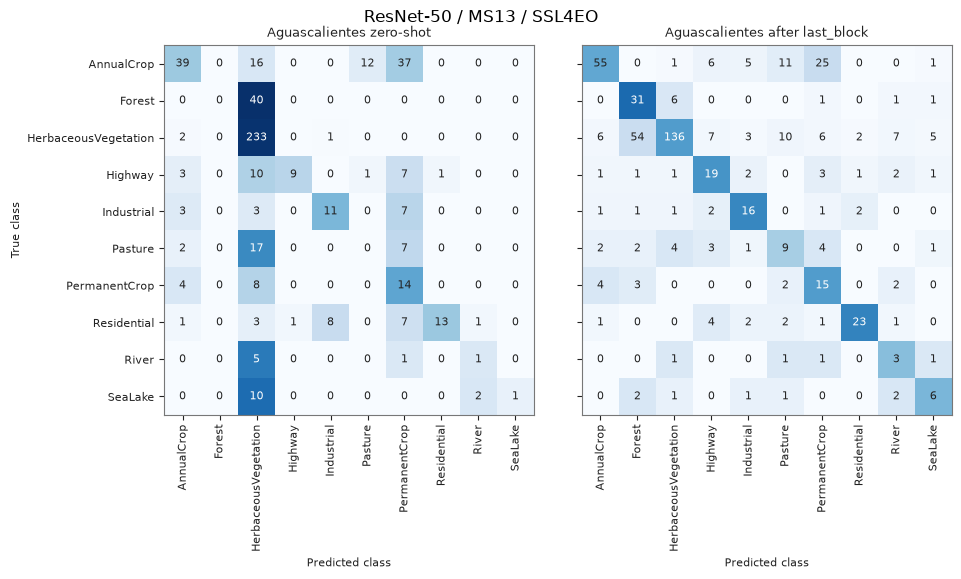

Aguascalientes zero-shot: largest error Forest -> HerbaceousVegetation, 40 patches (1.000 of the true Forest)
Aguascalientes after last_block: largest error HerbaceousVegetation -> Forest, 54 patches (0.229 of the true HerbaceousVegetation)


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5.5))
draw_stage(axes[0], winner, "zero_shot")
draw_stage(axes[1], winner, "last_block", show_ylabels=False)
fig.suptitle(runs[winner]["label"])
plt.tight_layout()
plt.show()
print_largest_error(winner, "zero_shot")
print_largest_error(winner, "last_block")

Any run at any stage. On EuroSAT the diagonal is almost full; in Aguascalientes, look at which classes
absorb the errors.

In [12]:
interact(plot_confusion, run_id=run_options, stage=list(STAGE_TITLES));

interactive(children=(Dropdown(description='run_id', index=2, options=(('ResNet-50 / RGB / ImageNet', 'resnet5…

## 5. CNN vs. ViT, and what each one costs (RQ-a, RQ-d, RQ-e)

The cost of every run, from the same summary as the paper's cost table: parameters, training time per
EuroSAT epoch, epochs trained, peak training memory and inference throughput on the EuroSAT test set.
All the costs were measured on one machine, so compare the runs with each other, not with other papers.

In [13]:
cost_table = pd.DataFrame(
    {
        "run": [run["label"] for run in data["runs"]],
        "params (M)": [run["summary"]["params"] / 1e6 for run in data["runs"]],
        "s / epoch": [run["summary"]["time_per_epoch_s"] for run in data["runs"]],
        "epochs": [run["summary"]["epochs"] for run in data["runs"]],
        "peak memory (GB)": [run["summary"]["peak_mem_mb"] / 1024 for run in data["runs"]],
        "patches/s": [run["summary"]["patches_per_s"] for run in data["runs"]],
    }
)
print(f"device: {', '.join(data['inputs']['devices'])}")
cost_table

device: mps


,run,params (M),s / epoch,epochs,peak memory (GB),patches/s
0,ResNet-50 / RGB / ImageNet,23.529,233.054,15,4.310,207.530
1,ResNet-50 / MS13 / ImageNet,23.560,252.111,10,4.310,183.837
2,ResNet-50 / MS13 / SSL4EO,23.560,251.720,15,4.310,183.457
3,EfficientNet-B0 / RGB / ImageNet,4.020,227.339,12,4.333,232.502
4,EfficientNet-B0 / MS13 / ImageNet,4.023,231.241,15,4.333,214.247
5,ViT-S / RGB / ImageNet,21.670,218.264,15,5.184,236.494
6,ViT-S / MS13 / ImageNet,22.653,236.986,14,5.251,198.646
7,ViT-S / MS13 / SSL4EO,22.653,237.213,15,5.251,199.410


Score against cost, one point per run, drawn as in the slides: the color is the architecture and the
marker is the input and the weights (circle RGB with ImageNet, square 13 bands with ImageNet, star
13 bands with SSL4EO-S12). A run is better when it is higher and, for throughput, further to the right.
Below the plot, the highest run overall and inside each group of input and weights, as the Explorer
says it. Look at whether the best score and the lowest cost belong to the same run.

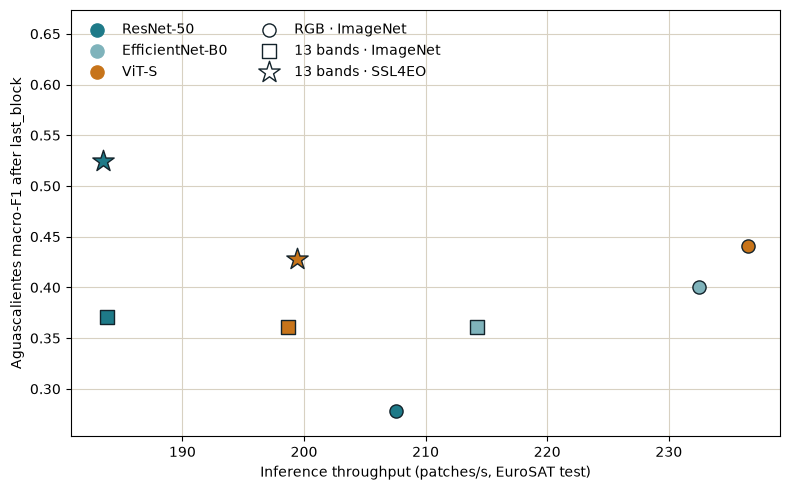

highest of all runs: ResNet-50 / MS13 / SSL4EO, 0.525
among the RGB · ImageNet runs: ViT-S, 0.441
among the 13 bands · ImageNet runs: ResNet-50, 0.371
among the 13 bands · SSL4EO runs: ResNet-50, 0.525


interactive(children=(Dropdown(description='y', options=('ags_last_block', 'ags_head', 'ags_zero_shot', 'euros…

In [14]:
SLIDE_COLORS = {"resnet50": "#1E7A88", "efficientnet_b0": "#7FB3BB", "vit_small": "#C7741A"}
SLIDE_INK = "#13232B"
SLIDE_GRID = "#D8D1C2"
MARKERS = {("rgb", "imagenet"): "o", ("ms13", "imagenet"): "s", ("ms13", "ssl4eo"): "*"}
SCORES = {
    "ags_last_block": "Aguascalientes macro-F1 after last_block",
    "ags_head": "Aguascalientes macro-F1 after head",
    "ags_zero_shot": "Aguascalientes macro-F1, zero-shot",
    "eurosat_macro_f1": "EuroSAT test macro-F1",
}
COSTS = {  # summary column -> (axis title, divisor)
    "patches_per_s": ("Inference throughput (patches/s, EuroSAT test)", 1),
    "params": ("Parameters (millions)", 1e6),
    "time_per_epoch_s": ("Training time per EuroSAT epoch (s)", 1),
    "peak_mem_mb": ("Peak training memory (GB)", 1024),
}


def marker_size(marker):
    # The star is drawn larger, as in the slide.
    if marker == "*":
        return 260
    return 90


def highest(run_list, y):
    # The run with the largest value of column y (the first one on a tie).
    best = run_list[0]
    for run in run_list:
        if run["summary"][y] > best["summary"][y]:
            best = run
    return best


def print_highest(y):
    # Highest run overall, then inside each group of input and weights with more than one run.
    best = highest(data["runs"], y)
    print(f"highest of all runs: {best['label']}, {best['summary'][y]:.3f}")
    for bands, init in MARKERS:
        group = [run for run in data["runs"] if run["bands"] == bands and run["init"] == init]
        if len(group) > 1:
            best = highest(group, y)
            group_name = f"{BANDS_LABELS[bands]} · {INIT_NAMES[init]}"
            value = best["summary"][y]
            print(f"among the {group_name} runs: {MODEL_NAMES[best['model']]}, {value:.3f}")


def plot_cost(y="ags_last_block", x="patches_per_s"):
    # Score (vertical) against one cost (horizontal) for every run.
    x_title, divisor = COSTS[x]
    fig, ax = plt.subplots(figsize=(8, 5))
    for run in data["runs"]:
        marker = MARKERS[(run["bands"], run["init"])]
        ax.scatter(
            run["summary"][x] / divisor,
            run["summary"][y],
            marker=marker,
            s=marker_size(marker),
            color=SLIDE_COLORS[run["model"]],
            edgecolor=SLIDE_INK,
            linewidth=1,
            zorder=3,
        )
    # Empty scatters only add legend entries: color = model, marker = input and weights.
    for model in MODEL_ORDER:
        ax.scatter([], [], marker="o", s=90, color=SLIDE_COLORS[model], label=MODEL_NAMES[model])
    for (bands, init), marker in MARKERS.items():
        label = f"{BANDS_LABELS[bands]} · {INIT_NAMES[init]}"
        ax.scatter(
            [],
            [],
            marker=marker,
            s=marker_size(marker),
            color="white",
            edgecolor=SLIDE_INK,
            label=label,
        )
    scores = [run["summary"][y] for run in data["runs"]]
    span = max(scores) - min(scores)
    ax.set_ylim(min(scores) - 0.1 * span, max(scores) + 0.6 * span)  # room for the legend
    ax.grid(color=SLIDE_GRID)
    ax.set_axisbelow(True)
    ax.set_xlabel(x_title)
    ax.set_ylabel(SCORES[y])
    ax.legend(loc="upper left", ncol=2, frameon=False)
    plt.tight_layout()
    plt.show()
    print_highest(y)


plot_cost()
interact(plot_cost, y=list(SCORES), x=list(COSTS));

The same fine-tuning mode does not train the same share of each model: `last_block` unfreezes the last
stage of ResNet-50, the last stage of EfficientNet-B0 and the last transformer block of ViT-S, and those
have very different sizes. `last_block_shares()` from `scripts/make_results.py` counts them without
downloading any weights. The check compares it with the value stored for the Explorer.

In [15]:
shares = last_block_shares()  # {model: trained parameters / all parameters}
for name, share in shares.items():
    same = math.isclose(share, data["last_block_share"][name])
    percent = 100 * share
    print(f"{MODEL_NAMES[name]:16s} last_block trains {percent:.0f} % | same as data: {same}")

ResNet-50        last_block trains 64 % | same as data: True
EfficientNet-B0  last_block trains 28 % | same as data: True
ViT-S            last_block trains 8 % | same as data: True


The selection rule (protocol section 8) was fixed before any result: the best Aguascalientes macro-F1
after `last_block` wins, and the runs within a small tie margin of the top (`TIE_MARGIN` in
`scripts/make_results.py`) go to the higher throughput. Here the
summary is rebuilt from the result JSONs with `load_results()` and `build_summary()`, and
`select_model()` is applied to all the runs and to the ImageNet runs only (where the three architectures
compete with the same weights).

In [16]:
results = load_results(RESULTS_DIR)
summary = build_summary(results, LOGS_DIR)
groups = {
    "all": list(summary["run_id"]),
    "imagenet": list(summary[summary["init"] == "imagenet"]["run_id"]),
}
for group_name, run_ids in groups.items():
    selection = select_model(summary, run_ids)
    print(f"among {group_name} runs: winner {runs[selection['winner']]['label']}")
    runner_up = runs[selection["runner_up"]]["label"]
    print(f"  margin over the runner-up ({runner_up}): {selection['margin']:.3f}")
    print(f"  tie-break applied: {selection['tie_break_applied']}")
    same = selection == data["selection"][group_name]
    print(f"  same as data['selection']['{group_name}']: {same}")

among all runs: winner ResNet-50 / MS13 / SSL4EO
  margin over the runner-up (ViT-S / RGB / ImageNet): 0.084
  tie-break applied: False
  same as data['selection']['all']: True
among imagenet runs: winner ViT-S / RGB / ImageNet
  margin over the runner-up (EfficientNet-B0 / RGB / ImageNet): 0.040
  tie-break applied: False
  same as data['selection']['imagenet']: True


## 6. Spatial split

The Aguascalientes cells are split into fine-tuning and test cells block by block, never cell by cell:
neighbouring cells look alike, so a test cell right next to a fine-tuning cell makes the test easier than
it should be. The figure puts the blocks (colored by split, as in Fig. 1 of the paper) over the labeling
previews, draws every labeled cell as a small square and marks in red the test cells that still touch a
fine-tuning cell across a block border. With `mode="random"` the same cells are split at random, one by
one, with the same number of fine-tuning and test cells: look at how many more red cells appear.

In [17]:
split = data["split"]
if split is None:
    print("data/ags/labels.csv not found, so the split cannot be drawn.")
    print("It comes with the v1.0 release: python scripts/download_release.py")
else:
    n_cells = split["block_cells"]
    print(f"fine-tune cells: {split['n_finetune']} | test cells: {split['n_test']}")
    print(f"block: {n_cells} x {n_cells} cells")

fine-tune cells: 561 | test cells: 541
block: 8 x 8 cells


In [18]:
BASEMAP_JPG = ROOT / "docs" / "explorer" / "basemap.jpg"
BASEMAP_JS = ROOT / "docs" / "explorer" / "basemap.js"


def read_basemap_position(path):
    # basemap.js has a comment line and one line "window.HYDROSCOPE_BASEMAP = {...};".
    for line in path.read_text().splitlines():
        if line.startswith(BASEMAP_PREFIX):
            return json.loads(line.removeprefix(BASEMAP_PREFIX).removesuffix(";"))
    raise ValueError(f"{path} has no line starting with {BASEMAP_PREFIX!r}")


def draw_basemap(ax):
    # The mosaic of previews, placed so that one grid cell is one unit (x = col, y = row).
    if not BASEMAP_JPG.exists() or not BASEMAP_JS.exists():
        print("no basemap: build it with python scripts/make_explorer_basemap.py")
        return
    position = read_basemap_position(BASEMAP_JS)
    left = position["col0"] - 0.5
    top = position["row0"] - 0.5
    extent = (left, left + position["n_cols"], top + position["n_rows"], top)
    ax.imshow(plt.imread(BASEMAP_JPG), extent=extent)


def draw_blocks(ax, cells, block_cells):
    # One square per block, in the color of its split.
    block_split = {}
    for row, col, split_name in cells:
        block_split[(row // block_cells, col // block_cells)] = split_name
    for (block_row, block_col), split_name in block_split.items():
        corner = (block_col * block_cells - 0.5, block_row * block_cells - 0.5)
        square = Rectangle(
            corner,
            block_cells,
            block_cells,
            color=SPLIT_COLORS[split_name],
            alpha=BLOCK_ALPHA,
            linewidth=0,
        )
        ax.add_patch(square)
    # Empty squares only add the block colors to the legend.
    for split_name, color in SPLIT_COLORS.items():
        label = f"{SPLIT_NAMES[split_name]} blocks"
        ax.add_patch(Rectangle((0, 0), 0, 0, color=color, alpha=BLOCK_ALPHA, label=label))

In [19]:
def touching_cells(cells, neighborhood):
    # (row, col) of the test cells with a fine-tune cell among their neighbours.
    # Same rule as count_test_touching_finetune, but returning the cells so we can draw them.
    finetune_cells = set()
    for row, col, split_name in cells:
        if split_name == "finetune":
            finetune_cells.add((row, col))
    touching = []
    for row, col, split_name in cells:
        if split_name != "test":
            continue
        for d_row, d_col in NEIGHBOR_OFFSETS[neighborhood]:
            if (row + d_row, col + d_col) in finetune_cells:
                touching.append((row, col))
                break
    return touching


def random_split(cells, seed):
    # Same cells and the same number of fine-tune and test cells, assigned at random one by one.
    rng = np.random.default_rng(seed)
    shuffled = rng.permutation([cell[2] for cell in cells])
    random_cells = []
    for cell, split_name in zip(cells, shuffled, strict=True):
        random_cells.append([cell[0], cell[1], str(split_name)])
    return random_cells

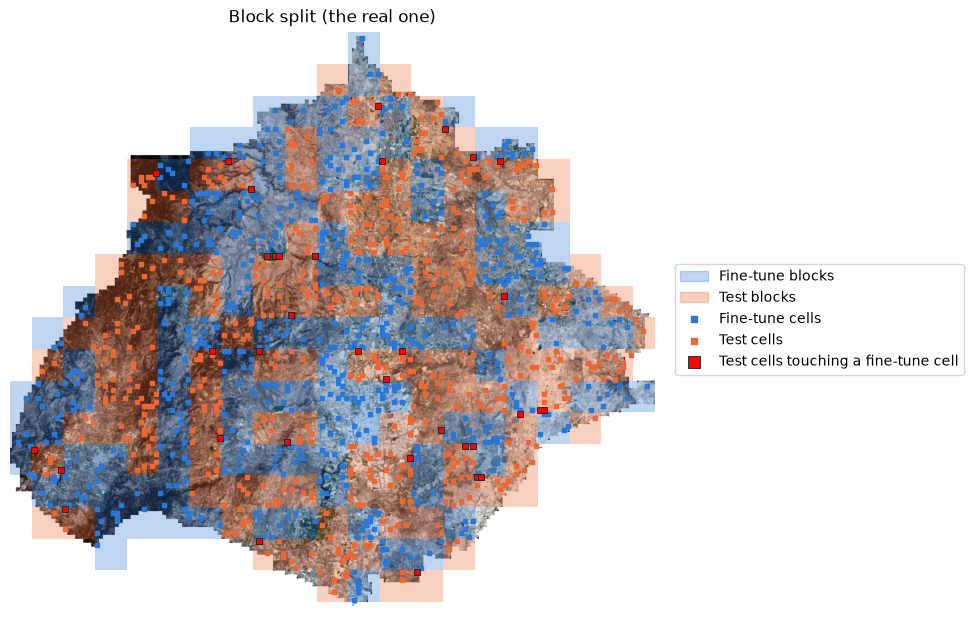

test cells touching a fine-tune cell (8 neighbours): 35 of 541


In [20]:
def plot_split(mode="blocks", seed=0, basemap=True):
    # Labeled cells on the previews: the real block split, or a random cell-by-cell split.
    if split is None:
        print("no split to draw (data/ags/labels.csv is missing)")
        return
    if mode == "blocks":
        cells = split["cells"]
    elif mode == "random":
        cells = random_split(split["cells"], seed)
    else:
        raise ValueError("mode must be 'blocks' or 'random'")
    touching = touching_cells(cells, split["neighborhood"])

    fig, ax = plt.subplots(figsize=(11, 7.5))  # wider: room for the legend on the right
    if basemap:
        draw_basemap(ax)
    if mode == "blocks":
        draw_blocks(ax, cells, split["block_cells"])
    for split_name, color in SPLIT_COLORS.items():
        rows = [cell[0] for cell in cells if cell[2] == split_name]
        cols = [cell[1] for cell in cells if cell[2] == split_name]
        ax.scatter(
            cols, rows, marker="s", s=5, color=color, label=f"{SPLIT_NAMES[split_name]} cells"
        )
    rows = [cell[0] for cell in touching]
    cols = [cell[1] for cell in touching]
    # Larger and outlined, so they stand out from the orange test cells.
    ax.scatter(
        cols,
        rows,
        marker="s",
        s=16,
        color="red",
        edgecolor=SLIDE_INK,
        linewidth=0.6,
        label="Test cells touching a fine-tune cell",
    )

    all_rows = [cell[0] for cell in split["cells"]]
    all_cols = [cell[1] for cell in split["cells"]]
    ax.set_xlim(min(all_cols) - 2, max(all_cols) + 2)
    ax.set_ylim(max(all_rows) + 2, min(all_rows) - 2)  # row 0 is north, so rows grow downwards
    ax.set_aspect("equal")
    ax.axis("off")
    ax.legend(
        loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=True, markerscale=2
    )  # outside, right
    if mode == "blocks":
        ax.set_title("Block split (the real one)")
    else:
        ax.set_title(f"Random cell-by-cell split, seed {seed} (simulation)")
    plt.show()
    print(
        f"test cells touching a fine-tune cell ({split['neighborhood']} neighbours): "
        f"{len(touching)} of {split['n_test']}"
    )


plot_split()

The count of the paper comes from `count_test_touching_finetune()` in `scripts/make_explorer_data.py`.
Called live on the real split it must give the value stored in `data["split"]`. Then the same count on
random cell-by-cell splits: this is a simulation made only for this notebook, not a result of the paper.

In [21]:
if split is not None:
    neighborhood = split["neighborhood"]
    count = count_test_touching_finetune(split["cells"], neighborhood)
    stored = split["test_touching_finetune"]
    red_cells = touching_cells(split["cells"], neighborhood)
    print(f"block split: {count} test cells touch a fine-tune cell")
    print(f"  same as data['split']['test_touching_finetune']: {count == stored}")
    print(f"  same as the red cells of the figure: {count == len(red_cells)}")

    random_counts = []
    for seed in range(20):
        random_cells = random_split(split["cells"], seed)
        random_counts.append(count_test_touching_finetune(random_cells, neighborhood))
    n_random = len(random_counts)
    print(f"simulation, not a paper result: {n_random} random splits (seeds 0 to {n_random - 1})")
    print(
        f"  min {min(random_counts)} | mean {np.mean(random_counts):.1f} | max {max(random_counts)}"
    )

block split: 35 test cells touch a fine-tune cell
  same as data['split']['test_touching_finetune']: True
  same as the red cells of the figure: True
simulation, not a paper result: 20 random splits (seeds 0 to 19)
  min 137 | mean 154.2 | max 171


In [22]:
# The menu version starts without the previews (tick "basemap" to add them): the photo is heavy,
# and every figure shown by interact is also stored in the saved notebook.
interact(plot_split, mode=["blocks", "random"], seed=(0, 19), basemap=False);

interactive(children=(Dropdown(description='mode', options=('blocks', 'random'), value='blocks'), IntSlider(va…

## 7. Code tour (live)

The functions behind each step of the study, called on tiny inputs. They are imported from
`src/hydroscope/`, the same code that trained and evaluated the models.

### 7.1 The grid

Every patch is one cell of a regular grid, named by its row and column (row 0 is north, column 0 is
west). Cells are grouped in square blocks, and the spatial split assigns whole blocks.

In [23]:
import inspect

from hydroscope.geo.grid import BLOCK_CELLS, GRID_M, block_id, cell_id

print(f"cell size: {GRID_M} m | block: {BLOCK_CELLS} x {BLOCK_CELLS} cells")
print(f"cell_id(74, 158)  = {cell_id(74, 158)}")
print(f"block_id(74, 158) = {block_id(74, 158)}\n")
print(inspect.getsource(block_id))

cell size: 640 m | block: 8 x 8 cells
cell_id(74, 158)  = r0074_c0158
block_id(74, 158) = b009_019

def block_id(row: int, col: int, block_cells: int = BLOCK_CELLS) -> str:
    """Block id ``b{row//8:03d}_{col//8:03d}`` of the 8 x 8-cell block containing the cell."""
    return f"b{row // block_cells:03d}_{col // block_cells:03d}"



### 7.2 The first layer for 13 bands

The ImageNet weights expect RGB. For a 13-band input, the protocol copies the R, G and B weights of the
first convolution to B04, B03 and B02 and gives every other band the mean of the three. We check it on a
tiny random weight of shape (out, in, k, k).

In [24]:
import torch

from hydroscope.data.eurosat import BAND_SETS
from hydroscope.models.factory import rgb_to_ms13_weight

torch.manual_seed(0)
rgb_weight = torch.randn(2, 3, 3, 3)  # (out, R G B, k, k)
ms13_weight = rgb_to_ms13_weight(rgb_weight)  # (2, 3, 3, 3) -> (2, 13, 3, 3)
print("shape:", tuple(ms13_weight.shape))

ms13_bands = list(BAND_SETS["ms13"])
for rgb_index, band in enumerate(BAND_SETS["rgb"]):  # B04, B03, B02 = R, G, B
    ms13_index = ms13_bands.index(band)
    same = torch.equal(ms13_weight[:, ms13_index], rgb_weight[:, rgb_index])
    print(f"{band} is input channel {ms13_index} and holds the {'RGB'[rgb_index]} weights: {same}")

mean_weight = rgb_weight.mean(dim=1)  # (2, 3, 3): mean over R, G, B
other_bands = [band for band in ms13_bands if band not in BAND_SETS["rgb"]]
checks = [
    torch.allclose(ms13_weight[:, ms13_bands.index(band)], mean_weight) for band in other_bands
]
print(f"the other {len(other_bands)} bands hold the mean of R, G and B: {all(checks)}")

shape: (2, 13, 3, 3)
B04 is input channel 3 and holds the R weights: True
B03 is input channel 2 and holds the G weights: True
B02 is input channel 1 and holds the B weights: True
the other 10 bands hold the mean of R, G and B: True


### 7.3 The three models

The three architectures come from timm. With `pretrained=False` nothing is downloaded: counting
parameters does not need the weights. The count is compared with the `params` column of the RGB runs.

In [25]:
import timm

from hydroscope.models.factory import TIMM_NAMES, count_params

rgb_params = {
    run["model"]: run["summary"]["params"] for run in data["runs"] if run["bands"] == "rgb"
}
models = {}
for name in MODEL_ORDER:
    models[name] = timm.create_model(TIMM_NAMES[name], pretrained=False, num_classes=len(classes))
    n_params = count_params(models[name])
    same = n_params == rgb_params[name]
    print(f"{MODEL_NAMES[name]:16s} {n_params / 1e6:6.2f} M parameters | same as summary: {same}")

ResNet-50         23.53 M parameters | same as summary: True
EfficientNet-B0    4.02 M parameters | same as summary: True


ViT-S             21.67 M parameters | same as summary: True


### 7.4 What `last_block` fine-tuning trains

`freeze_all_but()` turns off the gradients of every parameter and turns them back on only in the
modules returned by `last_block_modules()`. The share of trainable parameters must be the one counted
by `last_block_shares()` in section 5.

In [26]:
from hydroscope.models.factory import count_trainable_params, last_block_modules
from hydroscope.training.finetune import freeze_all_but

print(inspect.getsource(freeze_all_but))
for name, model in models.items():
    freeze_all_but(model, last_block_modules(model, name))
    share = count_trainable_params(model) / count_params(model)
    same = math.isclose(share, shares[name])
    print(
        f"{MODEL_NAMES[name]:16s} trains {100 * share:.0f} % | same as last_block_shares(): {same}"
    )

def freeze_all_but(model: nn.Module, trainable_modules: list[nn.Module]) -> None:
    """Set ``requires_grad=False`` everywhere, then ``True`` in ``trainable_modules``."""
    for param in model.parameters():
        param.requires_grad = False
    for module in trainable_modules:
        for param in module.parameters():
            param.requires_grad = True

ResNet-50        trains 64 % | same as last_block_shares(): True
EfficientNet-B0  trains 28 % | same as last_block_shares(): True
ViT-S            trains 8 % | same as last_block_shares(): True


### 7.5 Class weights for fine-tuning

The Aguascalientes labels are unbalanced, so the fine-tuning loss weights each class by its inverse
frequency: `n / (num_classes * count)`, where `n` is the number of patches. A rare class gets a large
weight and a frequent one a small weight, so every class pulls on the loss about the same. Here on a
made-up list of labels.

In [27]:
from hydroscope.training.finetune import class_weights

example_labels = [0, 0, 0, 0, 0, 0, 1, 1, 2]  # class 0 is frequent, class 2 is rare
n_classes = 3
weights = class_weights(example_labels, num_classes=n_classes)
for class_id in range(n_classes):
    count = example_labels.count(class_id)
    formula = f"{len(example_labels)} / ({n_classes} * {count})"
    print(f"class {class_id}: {count} patches -> {formula} = {weights[class_id]:.3f}")

class 0: 6 patches -> 9 / (3 * 6) = 0.500
class 1: 2 patches -> 9 / (3 * 2) = 1.500
class 2: 1 patches -> 9 / (3 * 1) = 3.000


### 7.6 The Earth Engine composite

The Aguascalientes image is a median composite of one month of Sentinel-2 L1C scenes, after masking the
pixels flagged as clouds or cirrus in the QA60 band. This code only runs with an Earth Engine account,
so here we only print it.

In [28]:
from hydroscope.geo.gee_export import (
    COLLECTION,
    END_DATE,
    START_DATE,
    build_composite,
    mask_s2_clouds,
)

print(f"collection {COLLECTION}, from {START_DATE} to {END_DATE} (end excluded)\n")
print(inspect.getsource(mask_s2_clouds))
print(inspect.getsource(build_composite))

collection COPERNICUS/S2_HARMONIZED, from 2024-04-01 to 2024-05-01 (end excluded)

def mask_s2_clouds(ee: Any, image: Any) -> Any:
    """Mask pixels with QA60 bit 10 (opaque clouds) or bit 11 (cirrus) set."""
    qa = image.select("QA60")
    clear = qa.bitwiseAnd(QA60_OPAQUE_MASK).eq(0).And(qa.bitwiseAnd(QA60_CIRRUS_MASK).eq(0))
    return image.updateMask(clear)

def build_composite(ee: Any, collection: Any, geometry: Any) -> Any:
    """Median composite (13 EuroSAT-ordered ``uint16`` bands) plus ``valid_obs``, clipped."""
    masked = collection.map(lambda img: mask_s2_clouds(ee, img))
    bands = masked.select(gee_band_names(), eurosat_band_names()).median().toUint16()
    valid_obs = masked.select("B2").count().rename(VALID_OBS_BAND).toUint16()
    return bands.addBands(valid_obs).select(export_band_names()).clip(geometry)



## 8. Conclusions

The three findings of the paper:

1. **The models were almost tied on EuroSAT, but all of them dropped sharply in Aguascalientes
   (RQ-a, RQ-b).** A near-perfect EuroSAT score does not guarantee a useful model in another region;
   the model has to be evaluated on local labels.
2. **Light fine-tuning won back only part of the drop (RQ-c).** Training the classifier alone (`head`)
   recovered little, and fine-tuning the last block (`last_block`) recovered more, but most of the drop
   remained in every run.
3. **The effect of the input bands and the weights depended on the model (RQ-d, RQ-e).** With ImageNet
   weights, 13 bands helped only ResNet-50 in Aguascalientes. With 13 bands, the SSL4EO-S12 runs scored
   higher after `last_block` than the ImageNet runs for ResNet-50 and ViT-S, but they also used another
   normalization, so the gap cannot be credited to the weights alone.

The numbers behind them, read from the results:

In [29]:
eurosat_f1 = [run["summary"]["eurosat_macro_f1"] for run in data["runs"]]
drops = [run["summary"]["drop"] for run in data["runs"]]
recovery_head = [run["summary"]["recovery_head"] for run in data["runs"]]
recovery_last_block = [run["summary"]["recovery_last_block"] for run in data["runs"]]
selection = data["selection"]["all"]

print(f"EuroSAT macro-F1: from {min(eurosat_f1):.3f} to {max(eurosat_f1):.3f}")
print(f"drop: from {min(drops):.3f} to {max(drops):.3f}")
print(
    f"largest recovery: head {max(recovery_head):.3f} | last_block {max(recovery_last_block):.3f}"
)
best_f1 = runs[winner]["summary"]["ags_last_block"]
print(f"selected model: {runs[winner]['label']}")
print(f"  last_block macro-F1 {best_f1:.3f}, {selection['margin']:.3f} above the runner-up")

EuroSAT macro-F1: from 0.983 to 0.993
drop: from 0.639 to 0.788
largest recovery: head 0.095 | last_block 0.268
selected model: ResNet-50 / MS13 / SSL4EO
  last_block macro-F1 0.525, 0.084 above the runner-up
